# Reconocimiento de texto (OCR) en español: de Tesseract a un VLM de última generación

**Universidad de Santiago de Chile (USACH)** · Diplomado de Inteligencia Artificial — Módulo de Visión por Computador
**Autor:** Diego Fischer

---

El **OCR** (*Optical Character Recognition*, reconocimiento óptico de caracteres) convierte el
texto contenido en una imagen —una foto, un escaneo, una captura de pantalla— en texto
editable. El flujo clásico tiene dos etapas: primero **detectar** dónde hay texto y luego
**reconocer** qué dice cada región.

Este cuaderno parte del enfoque tradicional con **Tesseract** y muestra un problema muy
concreto para el español: en su configuración por defecto Tesseract usa el modelo de idioma
**inglés**, que no incluye caracteres como la `ñ` ni las vocales acentuadas, por lo que los
confunde o los omite. A partir de ahí recorremos, de menor a mayor sofisticación, varias
alternativas modernas y terminamos con el estado del arte de 2026: los **modelos de
visión-lenguaje (VLM)**, que además de leer *entienden* el contenido.

**Ruta del cuaderno**

1. Punto de partida: Tesseract y por qué falla con la `ñ` (y su arreglo rápido).
2. Opción A — **EasyOCR**: aprendizaje profundo, fácil de usar, español nativo.
3. Opción B — **PaddleOCR (PP-OCRv5)**: OCR especializado de alto rendimiento con más de 100 idiomas.
4. **Top de línea — Qwen3-VL**: un VLM que transcribe respetando tildes, `ñ` y estructura.
5. Comparación práctica y recomendaciones según el caso de uso.

> **Sugerencia:** activa una GPU antes de empezar (*Entorno de ejecución → Cambiar tipo de
> entorno de ejecución → T4 GPU*). EasyOCR y, sobre todo, Qwen3-VL corren mucho más rápido con GPU.


## 0. Preparación: imágenes de ejemplo y utilidades

Descargamos dos imágenes: una con texto en inglés y otra con texto en español (con `ñ`,
tildes y signos de apertura `¿` `¡`), que será nuestro caso de prueba crítico.


In [1]:
# Descarga robusta de las imágenes de ejemplo (se fuerza la descarga con dl=1)
!wget -q -O ocr_example.png "https://www.dropbox.com/scl/fi/auwyxenioikbfdjq1lr8e/ocr_example.png?rlkey=3fza8gcsqwmnp7th15quc45ls&dl=1"
!wget -q -O ocr_ejemplo.png "https://www.dropbox.com/scl/fi/l305oyek9lwhigrr85lym/ocr_ejemplo.png?rlkey=6bpruyks9dzl478bqrztwqqtx&dl=1"

import os
for f in ["ocr_example.png", "ocr_ejemplo.png"]:
    ok = os.path.exists(f) and os.path.getsize(f) > 1000
    print(f"{f}: {'OK' if ok else 'REVISAR — no se descargó bien'} "
          f"({os.path.getsize(f) if os.path.exists(f) else 0} bytes)")


ocr_example.png: OK (64452 bytes)
ocr_ejemplo.png: OK (71737 bytes)


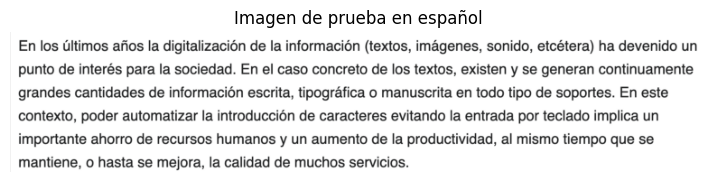

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

def mostrar(path, titulo=None, figsize=(9, 12)):
    '''Muestra una imagen con matplotlib.'''
    img = Image.open(path).convert("RGB")
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if titulo:
        plt.title(titulo)
    plt.show()
    return img

def dibujar_cajas(path, detecciones, figsize=(9, 12)):
    '''Dibuja cajas de texto sobre la imagen.
    detecciones es una lista de (caja, texto, confianza), donde caja son
    4 puntos [[x,y], ...]. Sirve para EasyOCR y PaddleOCR.'''
    import matplotlib.patches as patches
    img = Image.open(path).convert("RGB")
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)
    ax.axis("off")
    for caja, texto, conf in detecciones:
        xs = [p[0] for p in caja]
        ys = [p[1] for p in caja]
        ax.add_patch(patches.Polygon(list(zip(xs, ys)), closed=True,
                                     fill=False, linewidth=1.5, edgecolor="red"))
        ax.text(min(xs), min(ys) - 4, f"{texto} ({conf:.2f})",
                color="white", fontsize=7,
                bbox=dict(facecolor="red", alpha=0.6, pad=1, edgecolor="none"))
    plt.show()

# Vista previa de la imagen en español (nuestro caso crítico)
_ = mostrar("ocr_ejemplo.png", "Imagen de prueba en español")


## 1. Tesseract

**Tesseract** es el motor de OCR de código abierto más veterano y sigue siendo útil: corre
en CPU, es liviano y no necesita GPU. Lo usamos a través del envoltorio `pytesseract`.

El detalle clave: Tesseract necesita un **paquete de idioma** por cada lengua que quiera
reconocer. Al instalarlo solo viene el inglés (`eng`). Si le pasamos una imagen en español
sin indicarle el idioma, intentará leerla con el modelo inglés y ahí aparecen los errores
con `ñ`, tildes y signos `¿` `¡`.


In [3]:
# Instalamos Tesseract, el paquete de español y el envoltorio de Python
!sudo apt-get -qq update
!sudo apt-get -qq install -y tesseract-ocr tesseract-ocr-spa
!pip install -q pytesseract pillow


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package tesseract-ocr-spa.
(Reading database ... 118243 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-spa_1%3a4.00~git30-7274cfa-1.1_all.deb ...
Unpacking tesseract-ocr-spa (1:4.00~git30-7274cfa-1.1) ...
Setting up tesseract-ocr-spa (1:4.00~git30-7274cfa-1.1) ...


In [4]:
import pytesseract
from PIL import Image

img_es = Image.open("ocr_ejemplo.png")

# (1) Modo por defecto: modelo de idioma INGLÉS sobre un texto en español -> falla con ñ/tildes
texto_eng = pytesseract.image_to_string(img_es)  # lang='eng' implícito
print("===== Tesseract con modelo inglés (por defecto) =====")
print(texto_eng)


===== Tesseract con modelo inglés (por defecto) =====
En los Ultimos afios la digitalizaci6n de la informacién (textos, imagenes, sonido, etcétera) ha devenido un
punto de interés para la sociedad. En el caso concreto de los textos, existen y se generan continuamente
grandes cantidades de informacién escrita, tipografica 0 manuscrita en todo tipo de soportes. En este
contexto, poder automatizar la introduccién de caracteres evitando la entrada por teclado implica un
importante ahorro de recursos humanos y un aumento de la productividad, al mismo tiempo que se
mantiene, o hasta se mejora, la calidad de muchos servicios.



In [5]:
# (2) Arreglo directo dentro de Tesseract: usar el paquete de español que ya instalamos
texto_spa = pytesseract.image_to_string(img_es, lang="spa")
print("===== Tesseract con modelo español (lang='spa') =====")
print(texto_spa)


===== Tesseract con modelo español (lang='spa') =====
En los últimos años la digitalización de la información (textos, imágenes, sonido, etcétera) ha devenido un
punto de interés para la sociedad. En el caso concreto de los textos, existen y se generan continuamente
grandes cantidades de información escrita, tipográfica o manuscrita en todo tipo de soportes. En este
contexto, poder automatizar la introducción de caracteres evitando la entrada por teclado implica un
importante ahorro de recursos humanos y un aumento de la productividad, al mismo tiempo que se
mantiene, o hasta se mejora, la calidad de muchos servicios.



**Lectura de los resultados.** Con `lang='spa'` la mayoría de los caracteres del español
ya aparecen bien; ese es el arreglo más barato si te quedas con Tesseract. Aun así, Tesseract
tiende a fallar cuando el texto está inclinado, con poca resolución, sobre fondos complejos o
con tipografías poco comunes: reconoce carácter a carácter, sin "entender" el contexto. Para
esos casos conviene un motor basado en aprendizaje profundo.


## 2. Opción A — EasyOCR

**EasyOCR** usa redes neuronales para detectar y reconocer texto, y soporta más de 80 idiomas
(entre ellos el español) con una API mínima. Es la opción moderna más sencilla de poner en
marcha: se indica la lista de idiomas al crear el lector y devuelve, por cada región, la
**caja**, el **texto** y una **confianza**. La primera ejecución descarga los modelos, así que
tarda un poco más.


In [6]:
!pip install -q easyocr


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 12.9 MB/s eta 0:00:00


In [7]:
import easyocr

# gpu=True aprovecha la GPU si está activada; si no hay GPU, cámbialo a gpu=False
lector = easyocr.Reader(["es"], gpu=True)

resultados = lector.readtext("ocr_ejemplo.png")  # -> [(caja, texto, confianza), ...]

print("===== EasyOCR (español) =====")
for caja, texto, conf in resultados:
    print(f"[{conf:.2f}] {texto}")

# Texto completo concatenado
print("\n----- Texto reconstruido -----")
print(" ".join(t for _, t, _ in resultados))


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


===== EasyOCR (español) =====
[0.72] En los últimos años la digitalización de la información (textos, imágenes; sonido; etcétera) ha devenido un
[0.87] punto de interés para la sociedad. En el caso concreto de los textos,
[1.00] existen y se generan continuamente
[0.67] grandes cantidades de información escrita, tipográfica 0 manuscrita en todo tipo de soportes. En este
[0.63] contexto; poder automatizar la introducción de caracteres evitando la entrada por teclado implica un
[0.82] importante ahorro de recursos humanos y un aumento de la productividad, al mismo tiempo que se
[0.93] mantiene,
[0.54] hasta se mejora; la calidad de muchos servicios.

----- Texto reconstruido -----
En los últimos años la digitalización de la información (textos, imágenes; sonido; etcétera) ha devenido un punto de interés para la sociedad. En el caso concreto de los textos, existen y se generan continuamente grandes cantidades de información escrita, tipográfica 0 manuscrita en todo tipo de soportes. En es

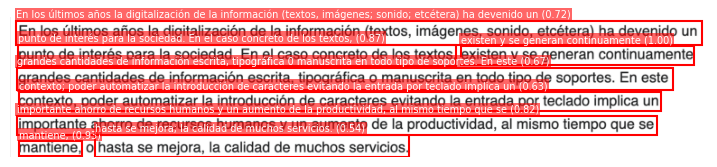

In [8]:
# Visualización de las regiones detectadas
dibujar_cajas("ocr_ejemplo.png", resultados)


## 3. Opción B — PaddleOCR (PP-OCRv5)

**PaddleOCR** (del ecosistema PaddlePaddle) es uno de los motores especializados más potentes
y rápidos. Su familia **PP-OCRv5** cubre más de 100 idiomas y entrega detección + reconocimiento
con coordenadas y confianza, con muy buena precisión en escenarios reales (documentos, letreros,
fotos). Para español se selecciona con `lang='es'`.

> **Nota de instalación.** PaddleOCR evoluciona rápido y la API cambia entre versiones mayores.
> Aquí instalamos la versión de CPU de PaddlePaddle (evita conflictos de CUDA en Colab) y el
> código maneja tanto la API nueva (`predict`) como la anterior (`ocr`). Si la instalación
> fallara por incompatibilidades de versión, puedes saltarte esta sección: EasyOCR y Qwen3-VL
> cubren el objetivo del cuaderno.


In [ ]:
!pip install -q paddlepaddle          # versión CPU (estable en Colab)
!pip install -q "paddleocr>=2.7"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 7.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 56.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 767.5/767.5 kB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.0/6.0 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 80.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118

In [ ]:
from paddleocr import PaddleOCR

# use_textline_orientation corrige texto rotado; lang='es' selecciona el modelo en español
try:
    ocr = PaddleOCR(use_textline_orientation=True, lang="es")
except TypeError:
    # Compatibilidad con versiones 2.x que usaban 'use_angle_cls'
    ocr = PaddleOCR(use_angle_cls=True, lang="es")

ruta = "ocr_ejemplo.png"

# --- Extracción defensiva: soporta la salida de PaddleOCR 3.x (predict) y 2.x (ocr) ---
detecciones = []  # (caja, texto, confianza)
try:
    salida = ocr.predict(ruta)            # API 3.x
    for res in salida:
        d = res if isinstance(res, dict) else getattr(res, "json", {}).get("res", res)
        polys = d.get("rec_polys", d.get("dt_polys", []))
        textos = d.get("rec_texts", [])
        scores = d.get("rec_scores", [1.0] * len(textos))
        for poly, txt, sc in zip(polys, textos, scores):
            caja = [[float(p[0]), float(p[1])] for p in poly]
            detecciones.append((caja, txt, float(sc)))
except AttributeError:
    salida = ocr.ocr(ruta, cls=True)      # API 2.x
    for linea in (salida[0] or []):
        caja, (txt, sc) = linea
        detecciones.append(([[float(x), float(y)] for x, y in caja], txt, float(sc)))

print("===== PaddleOCR (español) =====")
for _, txt, sc in detecciones:
    print(f"[{sc:.2f}] {txt}")

print("\n----- Texto reconstruido -----")
print(" ".join(t for _, t, _ in detecciones))


/usr/local/lib/python3.12/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-LCNet_x1_0_doc_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this no

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('UVDoc', None, None)
Using official model (UVDoc), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/UVDoc`.


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Using official model (PP-LCNet_x1_0_textline_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.


...

Creating model: ('PP-OCRv6_medium_det', None, None)
Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Creating model: ('PP-OCRv6_medium_rec', None, None)
Using official model (PP-OCRv6_medium_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

NotImplementedError: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)


In [ ]:
# Visualización de las regiones detectadas por PaddleOCR
if detecciones:
    dibujar_cajas("ocr_ejemplo.png", detecciones)
else:
    print("Sin detecciones para dibujar (revisa la instalación de PaddleOCR).")


## 4. Top de línea — Qwen3-VL (modelo de visión-lenguaje)

Aquí está el salto conceptual. Los motores anteriores hacen OCR "puro": localizan y transcriben
caracteres. Un **VLM (Vision-Language Model)** es un modelo multimodal que **ve la imagen y
razona sobre ella con lenguaje**. En la práctica, esto significa que no solo lee el texto: lo
interpreta en su contexto, respeta la ortografía del idioma (tildes, `ñ`, `¿` `¡`), maneja
tipografías difíciles, escritura a mano y estructura (títulos, listas, tablas), y puedes
pedirle el formato de salida que quieras mediante una instrucción en lenguaje natural.

Usamos **Qwen3-VL** (Alibaba), uno de los VLM abiertos de referencia en 2026. Su capacidad de
OCR multilingüe cubre decenas de idiomas y es robusta ante desenfoque, poca luz e inclinación.
Elegimos la variante **2B**, que entra cómodamente en una GPU T4 de Colab; con más memoria
puedes subir a 4B u 8B para máxima calidad.

> **Requiere GPU.** Asegúrate de tener activada la T4 (*Entorno de ejecución → Cambiar tipo de
> entorno de ejecución → T4 GPU*). El modelo se descarga la primera vez (unos minutos).


In [ ]:
# transformers >= 4.57 es necesario para Qwen3-VL
!pip install -q "transformers>=4.57.0" "qwen-vl-utils" accelerate


In [ ]:
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"   # cabe en T4; sube a 4B/8B si tienes más VRAM

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID, dtype="auto", device_map="auto"
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
print("Modelo cargado:", MODEL_ID)


In [ ]:
from qwen_vl_utils import process_vision_info

# La instrucción define exactamente qué queremos: transcripción fiel, sin inventar nada
instruccion = (
    "Actúa como un sistema de OCR de alta precisión. Transcribe fielmente TODO el texto "
    "visible en la imagen, respetando tildes, la letra ñ y los signos ¿ ¡. No traduzcas, "
    "no corrijas y no agregues comentarios: devuelve solo el texto tal como aparece, "
    "conservando los saltos de línea."
)

messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": "ocr_ejemplo.png"},
        {"type": "text",  "text": instruccion},
    ],
}]

# Preparación de entradas (texto + imagen)
text_prompt = processor.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)
image_inputs, video_inputs = process_vision_info(messages)
inputs = processor(
    text=[text_prompt], images=image_inputs, videos=video_inputs,
    padding=True, return_tensors="pt",
).to(model.device)

# Generación
with torch.no_grad():
    generated = model.generate(**inputs, max_new_tokens=1024)

# Nos quedamos solo con los tokens nuevos (la respuesta)
trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, generated)]
texto_vlm = processor.batch_decode(
    trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
)[0]

print("===== Qwen3-VL (transcripción) =====")
print(texto_vlm)


**Ventaja y advertencia.** El VLM suele entregar la transcripción más limpia en español,
incluyendo caracteres y signos que los motores clásicos suelen equivocar. La contraparte es
que, al ser un modelo generativo, puede **"alucinar"** (completar o inventar texto) si la
imagen es ambigua o la instrucción es vaga. Por eso conviene una instrucción estricta como la
de arriba y, en aplicaciones críticas, verificar la salida. Como bonus, puedes cambiar la
instrucción para pedir el resultado en **Markdown**, extraer solo ciertos campos o devolver
una **tabla** en formato estructurado.


In [ ]:
# Ejemplo extra: pedir la salida estructurada en Markdown (útil para documentos)
instruccion_md = (
    "Extrae el texto de la imagen y devuélvelo en Markdown, conservando títulos, listas y "
    "el orden de lectura. Respeta tildes y la ñ. No traduzcas ni agregues comentarios."
)
messages_md = [{
    "role": "user",
    "content": [
        {"type": "image", "image": "ocr_ejemplo.png"},
        {"type": "text",  "text": instruccion_md},
    ],
}]
tp = processor.apply_chat_template(messages_md, tokenize=False, add_generation_prompt=True)
ii, vi = process_vision_info(messages_md)
ins = processor(text=[tp], images=ii, videos=vi, padding=True, return_tensors="pt").to(model.device)
with torch.no_grad():
    gen = model.generate(**ins, max_new_tokens=1024)
tr = [o[len(i):] for i, o in zip(ins.input_ids, gen)]
print(processor.batch_decode(tr, skip_special_tokens=True)[0])


---
### Licencia

Este material se distribuye bajo licencia **Creative Commons Atribución 4.0 Internacional
(CC BY 4.0)**. Eres libre de compartir y adaptar el contenido, incluso con fines comerciales,
siempre que otorgues el crédito correspondiente.

**Autor:** Diego Fischer — Universidad de Santiago de Chile (USACH).
**Material base original:** Domingo Mery.
Texto completo de la licencia: https://creativecommons.org/licenses/by/4.0/deed.es
